In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

df = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "dengue_weekly.csv",
    parse_dates=["start_date", "end_date"],
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26753 entries, 0 to 26752
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   year        26753 non-null  int64         
 1   week        26753 non-null  int64         
 2   start_date  26753 non-null  datetime64[us]
 3   end_date    26753 non-null  datetime64[us]
 4   district    26753 non-null  str           
 5   cases       26753 non-null  int64         
dtypes: datetime64[us](2), int64(3), str(1)
memory usage: 1.2 MB


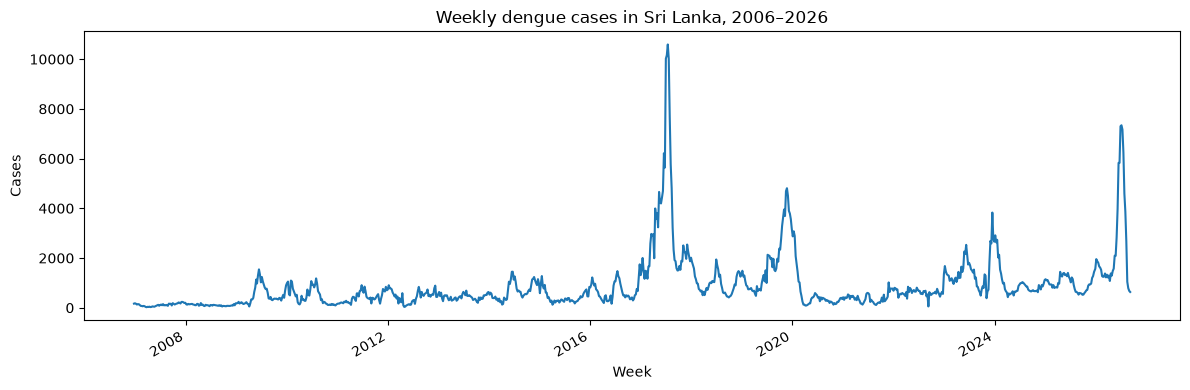

In [2]:
national = df.groupby("start_date")["cases"].sum()

fig, ax = plt.subplots(figsize=(12, 4))
national.plot(ax=ax)
ax.set_title("Weekly dengue cases in Sri Lanka, 2006–2026")
ax.set_xlabel("Week")
ax.set_ylabel("Cases")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_national_weekly_cases.png", dpi=150)
plt.show()

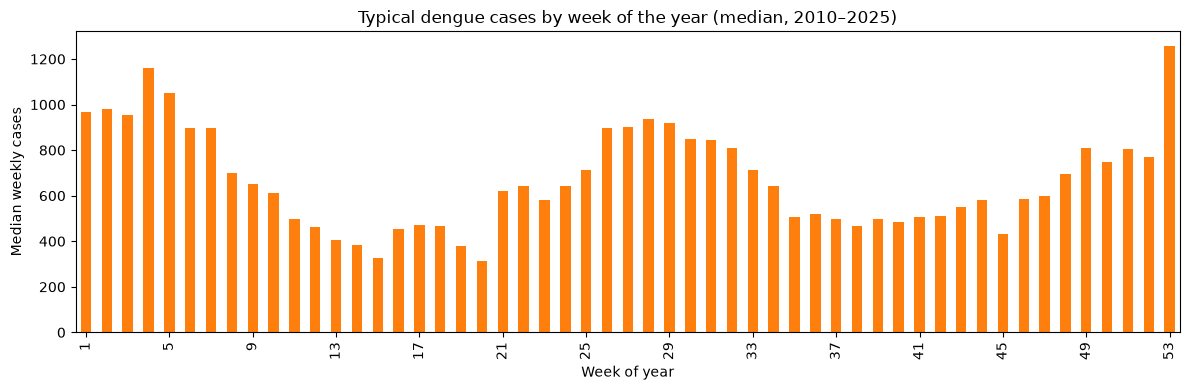

In [3]:
national_week = df.groupby(["year", "week"])["cases"].sum().reset_index()
national_week = national_week[national_week["year"].between(2010, 2025)]
season = national_week.groupby("week")["cases"].median()

fig, ax = plt.subplots(figsize=(12, 4))
season.plot(kind="bar", ax=ax, color="tab:orange")
ax.set_title("Typical dengue cases by week of the year (median, 2010–2025)")
ax.set_xlabel("Week of year")
ax.set_ylabel("Median weekly cases")
ax.set_xticks(range(0, len(season), 4))
ax.set_xticklabels(season.index[::4])
fig.tight_layout()
fig.savefig(FIG_DIR / "02_seasonality_by_week.png", dpi=150)
plt.show()